NLP SENTIMENT ANALYSIS
----------------------------------------
Training samples: 45615
Testing samples: 12284
Accuracy: 58.78 %
Precision: 0.5947
Recall: 0.5878
F1 Score: 0.5864

Classification Report:

              precision    recall  f1-score   support

    Negative       0.63      0.48      0.55      3972
     Neutral       0.61      0.64      0.62      5937
    Positive       0.50      0.64      0.56      2375

    accuracy                           0.59     12284
   macro avg       0.58      0.59      0.58     12284
weighted avg       0.59      0.59      0.59     12284



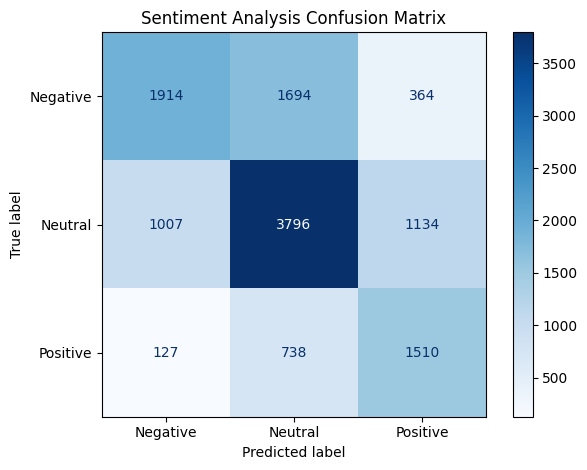


SAMPLE PREDICTIONS
I absolutely love this product, it is amazing! -> Positive
This is the worst experience I have ever had. -> Negative
The product arrived today and works as expected. -> Positive


In [4]:
%pip -q install scikit-learn requests matplotlib

import re
import requests
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay

base_url = "https://raw.githubusercontent.com/cardiffnlp/tweeteval/main/datasets/sentiment/"

def download_file(filename):
    response = requests.get(base_url + filename, timeout=60)
    response.raise_for_status()
    return response.text.splitlines()

train_text = download_file("train_text.txt")
train_y = np.array(download_file("train_labels.txt"), dtype=int)
test_text = download_file("test_text.txt")
test_y = np.array(download_file("test_labels.txt"), dtype=int)

def preprocess(text):
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " URL ", text)
    text = re.sub(r"@\w+", " USER ", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    text = re.sub(r"(.)\1{2,}", r"\1\1", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

train_text = [preprocess(t) for t in train_text]
test_text = [preprocess(t) for t in test_text]

vectorizer = FeatureUnion([
    ("word", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=150000,
        sublinear_tf=True,
        strip_accents="unicode")),
    ("char", TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        min_df=2,
        max_features=100000,
        sublinear_tf=True,
        max_df=0.98))])

X_train = vectorizer.fit_transform(train_text)
X_test = vectorizer.transform(test_text)

model = LinearSVC(C=1.0, max_iter=5000)
model.fit(X_train, train_y)
predictions = model.predict(X_test)

print("NLP SENTIMENT ANALYSIS")
print("-" * 40)
print("Training samples:", len(train_text))
print("Testing samples:", len(test_text))
print("Accuracy:", round(accuracy_score(test_y, predictions) * 100, 2), "%")
print("Precision:", round(precision_score(test_y, predictions, average="weighted", zero_division=0), 4))
print("Recall:", round(recall_score(test_y, predictions, average="weighted", zero_division=0), 4))
print("F1 Score:", round(f1_score(test_y, predictions, average="weighted", zero_division=0), 4))

print("\nClassification Report:\n")
print(classification_report(
    test_y,
    predictions,
    labels=[0, 1, 2],
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    test_y,
    predictions,
    labels=[0, 1, 2],
    display_labels=["Negative", "Neutral", "Positive"],
    cmap="Blues")
plt.title("Sentiment Analysis Confusion Matrix")
plt.tight_layout()
plt.show()

examples = [
    "I absolutely love this product, it is amazing!",
    "This is the worst experience I have ever had.",
    "The product arrived today and works as expected."]

print("\nSAMPLE PREDICTIONS")
for text in examples:
    features = vectorizer.transform([preprocess(text)])
    prediction = model.predict(features)[0]
    sentiment = {0: "Negative", 1: "Neutral", 2: "Positive"}[prediction]
    print(f"{text} -> {sentiment}")